Here you find the codes corresponding to student 1  to use them in the preprocessing pipeline 

In [ ]:
import pandas as pd 
import numpy as np
# Read the dataset:
df=pd.read_csv("data.csv")
print("Number of rows and columns in our dataset is: \t",df.shape)
print("Number of duplicates in our dataset is: \t",df.duplicated().sum())
print("Number of duplicates in key values in our dataset is: \t",df.duplicated(subset=["timestamp","sensor_node_id","field_zone"]).sum())
print("Number ofmissing values  in our dataset is: \t",df.isnull().sum().sum())
print(df.head(1))

Number of rows and columns in our dataset is: 	 (15000, 32)
Number of duplicates in our dataset is: 	 0
Number of duplicates in key values in our dataset is: 	 0
Number ofmissing values  in our dataset is: 	 0
             timestamp sensor_node_id field_zone   latitude  longitude  \
0  2024-01-01 00:00:00         SN_007     Zone_C  11.696902  78.726563   

  crop_type growth_stage  air_temperature_c  relative_humidity_pct  \
0    Tomato     Seedling              22.68                  87.98   

   soil_temperature_c  ...  leaf_wetness_pct  co2_ppm  evapotranspiration_mm  \
0                21.2  ...             62.35   418.77                   0.62   

   irrigation_status  irrigation_amount_l  water_flow_rate_l_min  \
0                Off                  0.0                    0.0   

   battery_level_pct  signal_strength_dbm  sensor_status  \
0              69.23               -86.89         Active   

   environmental_condition  
0            High_Humidity  

[1 rows x 32 columns]


In [2]:
import pandas as pd
import matplotlib.pyplot as plt 

Verification of Embalance classes to target variable:

In [3]:
TARGET='environmental_condition'
df= pd.read_csv("data.csv")
#Count the number of each class:
counts = df[TARGET].value_counts()
pct=(100*counts/len(df)).round(2)
table=pd.DataFrame({"count":counts,"percent":pct})
print(table)

# calculate max:min & compaire it with 1:3 :
ratio=counts.max()/counts.min()
print(f"imbalance ratio (max:min)={ratio:.2f}:1")
print("REAL dimbalance (ratio > 3):",ratio > 3)

                         count  percent
environmental_condition                
Optimal                   6383    42.55
Dry_Stress                3557    23.71
Adverse                   3361    22.41
High_Humidity             1094     7.29
Heat_Stress                605     4.03
imbalance ratio (max:min)=10.55:1
REAL dimbalance (ratio > 3): True


10.55 means that the target classes are imbalanced,with approximately 10 optimal instances for evry Heat_Stress instance , requiring imbalance handling. 

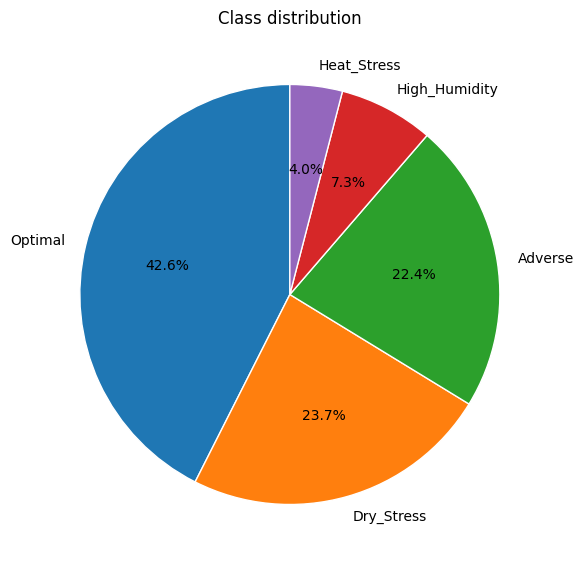

In [4]:
# Pie chart of the class proportions
plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
        wedgeprops={"edgecolor": "white"})
plt.title("Class distribution")
plt.tight_layout()
plt.savefig("class_pie.png", dpi=150)
plt.show()

Imputation : there is No missing values in our data set so the imputation process doasn't required.

Clean the dataset by dropping columns that provide leakage to target variable ["irrigation_status","irrigation_amount_l","water_flow_rate_l_min"] 

In [15]:
data_cleaned=pd.read_csv("data.csv")
print(data_cleaned.shape)
leak_cols=["irrigation_status","irrigation_amount_l","water_flow_rate_l_min"]
data_cleaned=data_cleaned.drop(columns=leak_cols)
data_cleaned.to_csv("data_clean.csv",index=False,encoding="utf-8")
print(data_cleaned.shape)

(15000, 32)
(15000, 29)


Encoding the categorical variable:                                                           
The modalities (N of classes) in our data are less than 10 (<10) so we apply the HotOne Encodig. 

In [14]:
from sklearn.preprocessing import OneHotEncoder
cat_cols = data_cleaned.select_dtypes(include=["object","category","bool"]).columns
print("The categorical columns are: \n: ",cat_cols.to_list())
# Encode the needed colums only:
categorical_cols=['crop_type', 'growth_stage','sensor_status']
encoder=OneHotEncoder(sparse_output=False,handle_unknown="ignore")
encoded=encoder.fit_transform(df[categorical_cols])
df_encoded=pd.concat([data_cleaned.drop(columns=categorical_cols),pd.DataFrame(encoded,columns=encoder.get_feature_names_out(categorical_cols),index=data_cleaned.index)],axis=1)
for col,categories in zip(categorical_cols,encoder.categories_):
    print(col,":",categories)

print(df_encoded.head(1))

coded_data=df_encoded.to_csv("coded_data.csv")
print(df_encoded.shape)

C:\Users\User Pc\AppData\Local\Temp\ipykernel_7320\29793985.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = data_cleaned.select_dtypes(include=["object","category","bool"]).columns


The categorical columns are: 
:  ['timestamp', 'sensor_node_id', 'field_zone', 'crop_type', 'growth_stage', 'sensor_status', 'environmental_condition']
crop_type : ['Cotton' 'Maize' 'Rice' 'Tomato' 'Wheat']
growth_stage : ['Flowering' 'Fruiting' 'Maturity' 'Seedling' 'Vegetative']
sensor_status : ['Active' 'Low_Battery' 'Weak_Signal']
             timestamp sensor_node_id field_zone   latitude  longitude  \
0  2024-01-01 00:00:00         SN_007     Zone_C  11.696902  78.726563   

   air_temperature_c  relative_humidity_pct  soil_temperature_c  \
0              22.68                  87.98                21.2   

   soil_moisture_pct  soil_ph  ...  crop_type_Tomato  crop_type_Wheat  \
0              56.98     6.75  ...               1.0              0.0   

   growth_stage_Flowering  growth_stage_Fruiting  growth_stage_Maturity  \
0                     0.0                    0.0                    0.0   

   growth_stage_Seedling  growth_stage_Vegetative  sensor_status_Active  \
0     

OneHOtEncoder creates a vertual columns for each class and use 0 or 1 to represent the class:                                                                                     
Example: sensor_status it create 3 other columns                          
 [sensor_status_Active , sensor_status_Low_Battery , sensor_status_Weak_Signal]         
 if our sensor is active so we find in the 3 columns the values :                         
 [1,0,0]

for this reason the number of columns in our dataset increases and be 39 column .    